In [1]:
import warnings
warnings.filterwarnings(action='ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
import seaborn as sns
import sklearn
from sklearn import datasets
sklearn.set_config(display='text')
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# k최근접 이웃 알고리즘으로 포지션을 예측할 데이터를 읽어서 전처리한다.

## k최근접 이웃 알고리즘으로 포지션을 예측할 데이터를 읽어온다.

Player(선수 이름), Pos(포지션), 3P(3점슛), 2P(2점슛), TRB(리바운드), AST(어시스트), STL(스틸), BLK(블록슛)

In [2]:
basketball_stat_df = pd.read_csv('./data/basketball_stat.csv')
basketball_stat_df

,Player,Pos,3P,2P,TRB,AST,STL,BLK
0,Alex Abrines,SG,1.4,0.6,1.3,0.6,0.5,0.1
1,Steven Adams,C,0.0,4.7,7.7,1.1,1.1,1.0
2,Alexis Ajinca,C,0.0,2.3,4.5,0.3,0.5,0.6
3,Chris Andersen,C,0.0,0.8,2.6,0.4,0.4,0.6
4,Will Barton,SG,1.5,3.5,4.3,3.4,0.8,0.5
...,...,...,...,...,...,...,...,...
95,Nikola Vucevic,C,0.3,6.1,10.4,2.8,1.0,1.0
96,Dwyane Wade,SG,0.8,6.2,4.5,3.8,1.4,0.7
97,Dion Waiters,SG,1.8,4.3,3.3,4.3,0.9,0.4
98,Hassan Whiteside,C,0.0,7.0,14.1,0.7,0.7,2.1


In [3]:
basketball_stat_df.Pos.value_counts()

Pos
SG    50
C     50
Name: count, dtype: int64

## 분석할 데이터를 결정하기 위해서 데이터를 시각화 해 본다.

2P와 STL의 Pos별 분포를 확인한다.

<Figure size 800x600 with 0 Axes>

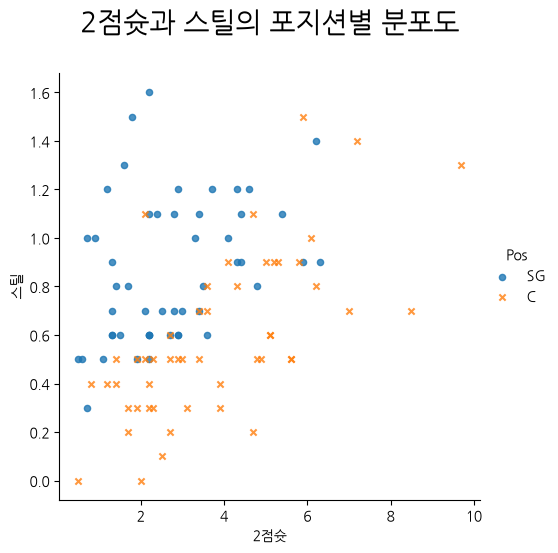

In [4]:
plt.figure(figsize=[8, 6])
sns.lmplot(
    data=basketball_stat_df, x='2P', y='STL', fit_reg=False, # 전체 데이터, x축으로 사용할 데이터, y축으로 사용할 데이터, 회귀선 표시 여부
    hue='Pos', # 그래프에 표시되는 마커의 색상 지정 => 범례가 자동으로 표시된다.
    scatter_kws={'s': 20}, # 그래프에 표시되는 마커의 크기 지정
    markers=['o', 'x'] # 그래프에 표시되는 마커의 종류 지정
)
plt.title('2점슛과 스틸의 포지션별 분포도', pad=30, fontsize=20)
plt.xlabel('2점슛')
plt.ylabel('스틸')
plt.show()

2P와 AST의 Pos별 분포를 확인한다.

<Figure size 800x600 with 0 Axes>

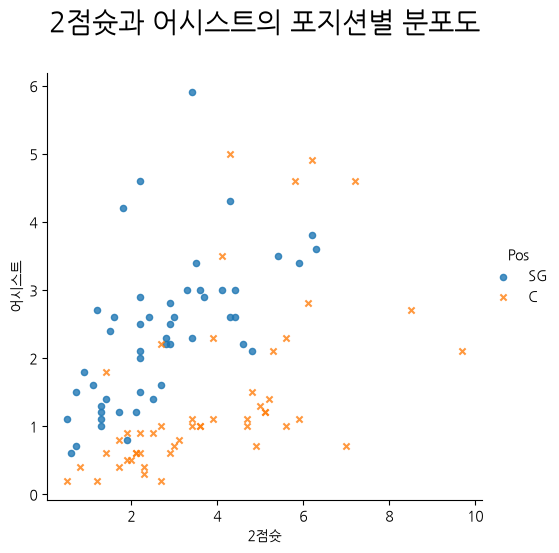

In [5]:
plt.figure(figsize=[8, 6])
sns.lmplot(data=basketball_stat_df, x='2P', y='AST', fit_reg=False, hue='Pos', scatter_kws={'s': 20}, markers=['o', 'x'])
plt.title('2점슛과 어시스트의 포지션별 분포도', pad=30, fontsize=20)
plt.xlabel('2점슛')
plt.ylabel('어시스트')
plt.show()

3P와 TRB의 Pos별 분포를 확인한다.

<Figure size 800x600 with 0 Axes>

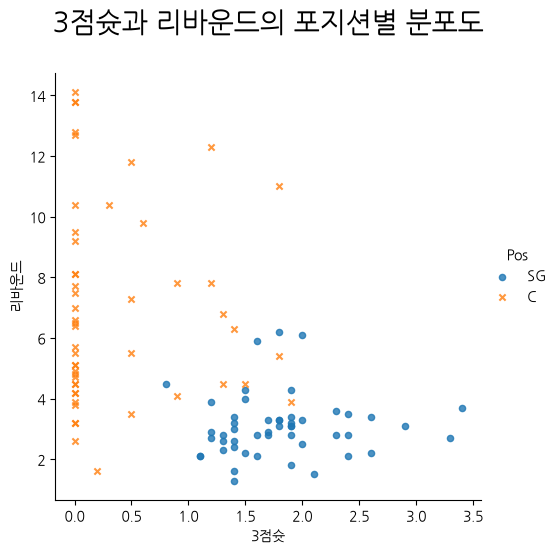

In [6]:
plt.figure(figsize=[8, 6])
sns.lmplot(data=basketball_stat_df, x='3P', y='TRB', fit_reg=False, hue='Pos', scatter_kws={'s': 20}, markers=['o', 'x'])
plt.title('3점슛과 리바운드의 포지션별 분포도', pad=30, fontsize=20)
plt.xlabel('3점슛')
plt.ylabel('리바운드')
plt.show()

3P와 BLK의 Pos별 분포를 확인한다.

<Figure size 800x600 with 0 Axes>

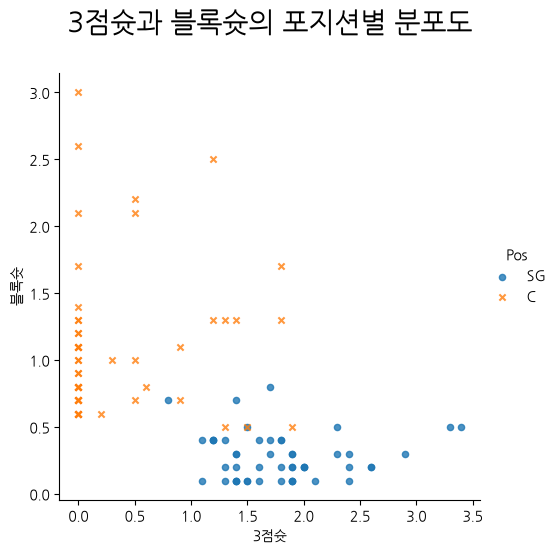

In [7]:
plt.figure(figsize=[8, 6])
sns.lmplot(data=basketball_stat_df, x='3P', y='BLK', fit_reg=False, hue='Pos', scatter_kws={'s': 20}, markers=['o', 'x'])
plt.title('3점슛과 블록슛의 포지션별 분포도', pad=30, fontsize=20)
plt.xlabel('3점슛')
plt.ylabel('블록슛')
plt.show()

## 데이터 전처리

drop() 메소드로 Player, 2P, AST, STL 피처를 삭제한다.

In [8]:
basketball_stat_df.drop(['Player', '2P', 'AST', 'STL'], axis=1, inplace=True)
basketball_stat_df

,Pos,3P,TRB,BLK
0,SG,1.4,1.3,0.1
1,C,0.0,7.7,1.0
2,C,0.0,4.5,0.6
3,C,0.0,2.6,0.6
4,SG,1.5,4.3,0.5
...,...,...,...,...
95,C,0.3,10.4,1.0
96,SG,0.8,4.5,0.7
97,SG,1.8,3.3,0.4
98,C,0.0,14.1,2.1


## 데이터를 학습 데이터와 테스트 데이터로 나눈다.

In [9]:
train, test = train_test_split(basketball_stat_df, train_size=0.8)
print(train.shape, test.shape)

(80, 4) (20, 4)


# 최적의 k최근접 이웃 파라미터를 찾는다.

사이킷런 라이브러리의 cross_val_score() 함수로 k-fold 교차 검증을 사용해서 k최근접 이웃 알고리즘의 조절 가능한 단 하나의 변수(n_neighbors, 하이퍼파라미터)값 k를 찾는다.

k-fold 교차 검증은 학습 데이터를 k개로 나눠서 k번 정확도를 검증하는 방법이다.

<img src="k-fold.png" width="600" align="left" />

최적의 k값을 찾기 위해서 교차 검증을 수행할 k값의 범위를 3부터 학습 데이터 개수의 절반까지 홀수로 지정한다.

In [10]:
k_list = []
for i in range(3, train.shape[0] // 2, 2):
    k_list.append(i)
print(k_list)

[3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39]


In [11]:
k_list = [i for i in range(3, train.shape[0] // 2, 2)]
print(k_list)

[3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39]


## 10-fold 교차 검증

학습 데이터를 10개의 조각으로 나누고 1각을 검증(validation) 데이터로 사용하고 나머지 9조각을 학습 데이터로 사용해서 1번째 조각부터 10번째 조각까지 각각 1번씩 검증하고 10번의 검증 결과를 나눈 평균을 검증 결과 점수로 한다.

교차 검증을 사용하기 위해서 cross_val_score 함수를 import 한다.

cross_val_score(model, x, y, scoring, cv)  
model: 교차 검증을 실행할 머신러닝 모델  
x: 독립 변수, 학습 데이터(피처)  
y: 종속 변수, 학습 데이터의 레이블(클래스, 타겟, 실제값, 관측값, 정답)  
scoring: 교차 검증에 사용할 평가 지표 => 정확도를 의미하는 accuracy를 사용한다.  
cv: 교차 검증시 사용하는 조각의 개수

In [12]:
from sklearn.model_selection import cross_val_score

In [13]:
# 각각의 k별 10-fold 교차 검증 결과의 평균을 기억할 빈 리스트를 선언한다.
scores = []
# 교차 검증을 하기 위해서 학습 데이터를 피쳐와 레이블로 분리한다.
x_train = train[['3P', 'TRB', 'BLK']]
y_train = train['Pos']

10-fold 교차 검증을 최적의 k값 후보(k_list)의 개수 만큼 반복하며 10-fold 교차 검증 결과를 scores에 저장한다.

In [14]:
for k in k_list:
    # 최적의 k값 후보를 n_neighbors로 지정해서 k최근접 이웃 알고리즘 모델을 만든다.
    model = KNeighborsClassifier(n_neighbors=k)
    # print(model)
    score = cross_val_score(model, x_train, y_train, scoring='accuracy', cv=10)
    # print(score, score.mean())
    scores.append(score.mean())
    print(f'k: {k:2d}, 각 폴드별 교차 검증 결과: {score}, 각 폴드별 교차 검증 결과의 평균: {score.mean()}')

k:  3, 각 폴드별 교차 검증 결과: [0.875 1.    1.    0.875 1.    0.875 0.875 0.875 0.875 0.875], 각 폴드별 교차 검증 결과의 평균: 0.9125
k:  5, 각 폴드별 교차 검증 결과: [0.875 0.75  1.    1.    0.875 0.875 0.875 0.875 0.875 0.875], 각 폴드별 교차 검증 결과의 평균: 0.8875
k:  7, 각 폴드별 교차 검증 결과: [0.875 0.75  1.    0.875 1.    0.875 0.875 0.875 0.875 1.   ], 각 폴드별 교차 검증 결과의 평균: 0.9
k:  9, 각 폴드별 교차 검증 결과: [0.875 0.75  1.    1.    1.    0.875 0.875 0.875 0.875 1.   ], 각 폴드별 교차 검증 결과의 평균: 0.9125
k: 11, 각 폴드별 교차 검증 결과: [0.875 0.875 1.    1.    1.    0.875 0.875 0.875 0.875 1.   ], 각 폴드별 교차 검증 결과의 평균: 0.925
k: 13, 각 폴드별 교차 검증 결과: [0.875 0.875 1.    1.    1.    0.875 0.875 0.875 0.875 1.   ], 각 폴드별 교차 검증 결과의 평균: 0.925
k: 15, 각 폴드별 교차 검증 결과: [0.875 0.875 1.    1.    1.    0.875 0.875 0.875 0.875 1.   ], 각 폴드별 교차 검증 결과의 평균: 0.925
k: 17, 각 폴드별 교차 검증 결과: [0.875 0.875 1.    1.    1.    0.875 0.875 0.875 0.875 1.   ], 각 폴드별 교차 검증 결과의 평균: 0.925
k: 19, 각 폴드별 교차 검증 결과: [0.875 0.875 1.    1.    1.    0.875 0.875 0.875 0.875 1.   ], 각 폴드별 교차 검증 결과의 평

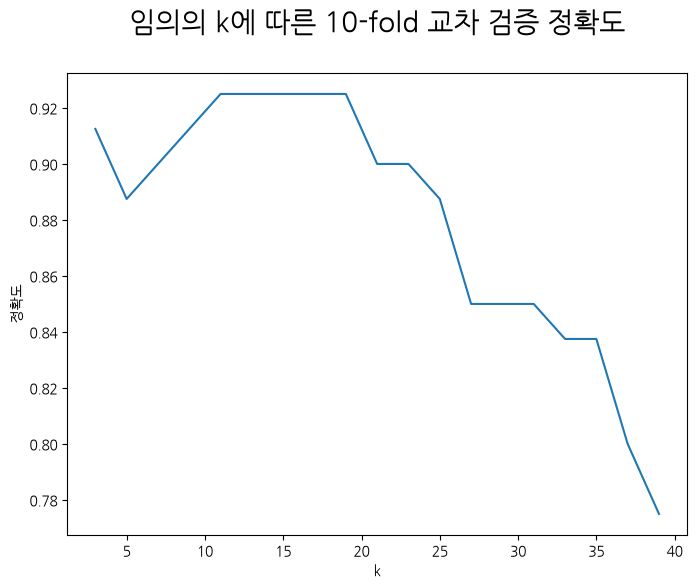

In [15]:
plt.figure(figsize=[8, 6])
plt.plot(k_list, scores)
plt.title('임의의 k에 따른 10-fold 교차 검증 정확도', pad=30, fontsize=20)
plt.xlabel('k')
plt.ylabel('정확도')
plt.show()

In [16]:
print(max(scores))
# index() 메소드는 인수로 지정한 값이 최초로 출현하는 인덱스를 리턴한다.
k = k_list[scores.index(max(scores))]
print(f'최적의 k: {k}')

0.925
최적의 k: 11


# 최적의 k를 사용해서 k최근접 이웃 모델을 테스트 한다.

최적의 k를 이용해서 모델을 만들고 학습시킨다.

In [17]:
x_train = train[['3P', 'TRB', 'BLK']]
y_train = train['Pos']

model = KNeighborsClassifier(n_neighbors=k)
model.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=11)

최적의 k를 이용해서 학습시킨 모델을 테스트 데이터로 예측한다.

In [18]:
x_test = test[['3P', 'TRB', 'BLK']]
y_test = test['Pos']

predict = model.predict(x_test)
print(predict)

['SG' 'C' 'C' 'C' 'C' 'C' 'SG' 'C' 'C' 'C' 'C' 'SG' 'C' 'C' 'C' 'SG' 'SG'
 'SG' 'SG' 'C']


테스트 데이터로 예측한 모델의 정확도를 계산한다.

In [19]:
accuracy = accuracy_score(y_test, predict)
print(f'정확도: {accuracy:.2%}')

정확도: 85.00%


In [20]:
pd.DataFrame({'실제값': y_test, '예측값': predict})

,실제값,예측값
20,SG,SG
31,C,C
30,C,C
5,SG,C
27,C,C
33,C,C
47,SG,SG
48,C,C
44,C,C
75,C,C


# 완성된 모델 사용하기

In [35]:
x = {'3P': [0, 3.9], 'TRB': [1, 0.1], 'BLK': [7.7, 0.3], 'Pos': ['C', 'SG']}
df = pd.DataFrame(x)
df

,3P,TRB,BLK,Pos
0,0.0,1.0,7.7,C
1,3.9,0.1,0.3,SG


In [36]:
x_test = df[['3P', 'TRB', 'BLK']]
y_test = df['Pos']

In [37]:
predict = model.predict(x_test)
print(predict)
accuracy = accuracy_score(y_test, predict)
print(f'정확도: {accuracy:.2%}')

['C' 'SG']
정확도: 100.00%


In [38]:
pd.DataFrame({'실제값': y_test, '예측값': predict})

,실제값,예측값
0,C,C
1,SG,SG
